# JardinerIA — Entrenamiento y comparación de modelos (Hito 2)

Este notebook compara, sobre el dataset **simulado**, tres enfoques para estimar el **estado** actual de la planta
(Saludable / Atención / Crítico) y su **tendencia a 3 días** (Mejora / Estable / Empeora):

1. **Solo reglas** (línea base): el motor de reglas aplicado al reporte observado.
2. **Random Forest** y **Gradient Boosting** (scikit-learn).
3. **Perceptrón multicapa en Keras** (se ejecuta solo si TensorFlow está instalado).

**Advertencia de validez.** Los datos son simulados y las etiquetas salen de la base de conocimiento.
Las métricas miden la coherencia con ese conocimiento y la capacidad de ver a través del ruido de reporte,
no el desempeño con plantas reales.

La partición (70/15/15) se hizo **por planta**, no por día. Se elige el mejor modelo con **validación** y
solo entonces se reporta **prueba**.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import f1_score, accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

from simulator.caracteristicas import construir_caracteristicas, estado_reglas, tendencia_reglas

SEMILLA = 0
ESTADOS = ["Saludable", "Atención", "Crítico"]
TENDENCIAS = ["Mejora", "Estable", "Empeora"]

## 1. Datos y características

In [2]:
df = pd.read_csv(RAIZ / "data" / "dataset_simulado.csv")
X, d = construir_caracteristicas(df)

tr = d["particion"] == "entrenamiento"
va = d["particion"] == "validacion"
te = d["particion"] == "prueba"
print("Filas:", len(d), "| plantas:", d["planta_id"].nunique(), "| características:", X.shape[1])
print(d["particion"].value_counts().to_dict())
print("\nEstado (proporción):\n", d["estado"].value_counts(normalize=True).round(3).to_string())

Filas: 18000 | plantas: 600 | características: 46
{'entrenamiento': 12600, 'prueba': 2700, 'validacion': 2700}

Estado (proporción):
 estado
Saludable    0.495
Crítico      0.299
Atención     0.206


## 2. Estado actual (3 clases)

In [3]:
def metricas_estado(y, p):
    return {
        "macro-F1": f1_score(y, p, average="macro"),
        "exactitud": accuracy_score(y, p),
        "recall Crítico": recall_score(y, p, labels=["Crítico"], average=None)[0],
    }

y = d["estado"]
modelos_estado = {
    "Solo reglas": None,
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEMILLA, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=SEMILLA),
}
pred_val, pred_te, filas = {}, {}, []
for nombre, mo in modelos_estado.items():
    if mo is None:
        pv, pt = estado_reglas(d[va]), estado_reglas(d[te])
    else:
        mo.fit(X[tr], y[tr])
        pv, pt = mo.predict(X[va]), mo.predict(X[te])
    pred_val[nombre], pred_te[nombre] = pv, pt
    filas.append({"modelo": nombre, **{f"val {k}": v for k, v in metricas_estado(y[va], pv).items()},
                  **{f"prueba {k}": v for k, v in metricas_estado(y[te], pt).items()}})
tabla_estado = pd.DataFrame(filas).set_index("modelo").round(3)
tabla_estado

,val macro-F1,val exactitud,val recall Crítico,prueba macro-F1,prueba exactitud,prueba recall Crítico
modelo,,,,,,
Solo reglas,0.776,0.803,0.900,0.778,0.787,0.889
Random Forest,0.840,0.881,0.932,0.833,0.857,0.917
Gradient Boosting,0.831,0.873,0.927,0.832,0.854,0.908


Mejor modelo de estado según validación: Random Forest


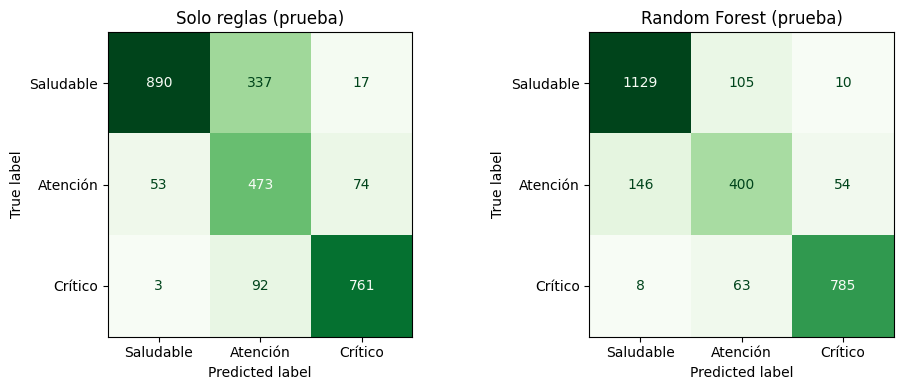

Recall por clase en prueba:
  Solo reglas          {'Saludable': 0.715, 'Atención': 0.788, 'Crítico': 0.889}
  Random Forest        {'Saludable': 0.908, 'Atención': 0.667, 'Crítico': 0.917}


In [4]:
mejor_estado = tabla_estado["val macro-F1"].idxmax()
print("Mejor modelo de estado según validación:", mejor_estado)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, nombre in zip(ax, ["Solo reglas", mejor_estado]):
    cm = confusion_matrix(y[te], pred_te[nombre], labels=ESTADOS)
    ConfusionMatrixDisplay(cm, display_labels=ESTADOS).plot(ax=a, colorbar=False, cmap="Greens")
    a.set_title(f"{nombre} (prueba)")
plt.tight_layout(); plt.show()

print("Recall por clase en prueba:")
for nombre in ["Solo reglas", mejor_estado]:
    rec = recall_score(y[te], pred_te[nombre], labels=ESTADOS, average=None)
    print(f"  {nombre:20s}", {k: round(float(v), 3) for k, v in zip(ESTADOS, rec)})

## 3. Tendencia a 3 días (3 clases)

In [5]:
ok = d["tendencia"].notna()
yt = d["tendencia"]

def metricas_tend(y_, p):
    return {"macro-F1": f1_score(y_, p, average="macro"), "exactitud": accuracy_score(y_, p)}

filas, pred_t_te = [], {}
bases = {
    "Siempre 'Estable'": lambda m: np.array(["Estable"] * int(m.sum())),
    "Reglas (extrapolación)": lambda m: tendencia_reglas(d[m]),
}
for nombre, f in bases.items():
    pv, pt = f(va & ok), f(te & ok)
    pred_t_te[nombre] = pt
    filas.append({"modelo": nombre, **{f"val {k}": v for k, v in metricas_tend(yt[va & ok], pv).items()},
                  **{f"prueba {k}": v for k, v in metricas_tend(yt[te & ok], pt).items()}})

modelos_t = {
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEMILLA, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=SEMILLA),
}
fitted_t = {}
for nombre, mo in modelos_t.items():
    mo.fit(X[tr & ok], yt[tr & ok]); fitted_t[nombre] = mo
    pv, pt = mo.predict(X[va & ok]), mo.predict(X[te & ok])
    pred_t_te[nombre] = pt
    filas.append({"modelo": nombre, **{f"val {k}": v for k, v in metricas_tend(yt[va & ok], pv).items()},
                  **{f"prueba {k}": v for k, v in metricas_tend(yt[te & ok], pt).items()}})
tabla_tend = pd.DataFrame(filas).set_index("modelo").round(3)
tabla_tend

,val macro-F1,val exactitud,prueba macro-F1,prueba exactitud
modelo,,,,
Siempre 'Estable',0.182,0.376,0.163,0.324
Reglas (extrapolación),0.301,0.304,0.304,0.303
Random Forest,0.519,0.521,0.489,0.492
Gradient Boosting,0.504,0.505,0.480,0.481


Mejor modelo de tendencia según validación: Random Forest


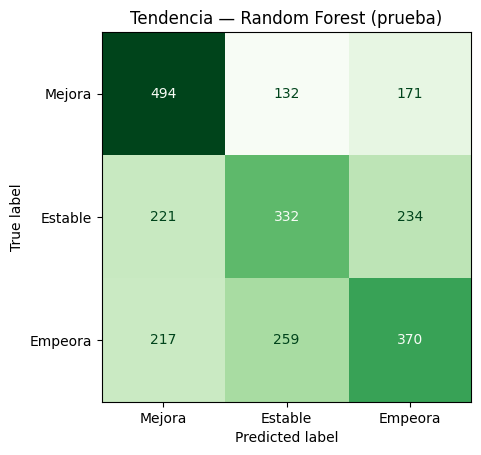

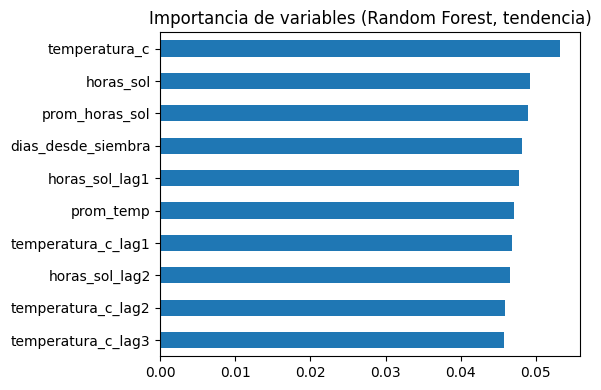

In [6]:
mejor_tend = tabla_tend.loc[list(modelos_t), "val exactitud"].idxmax()
print("Mejor modelo de tendencia según validación:", mejor_tend)

cm = confusion_matrix(yt[te & ok], pred_t_te[mejor_tend], labels=TENDENCIAS)
ConfusionMatrixDisplay(cm, display_labels=TENDENCIAS).plot(colorbar=False, cmap="Greens")
plt.title(f"Tendencia — {mejor_tend} (prueba)"); plt.show()

imp = pd.Series(fitted_t["Random Forest"].feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp[::-1].plot.barh(figsize=(6, 4), title="Importancia de variables (Random Forest, tendencia)"); plt.tight_layout(); plt.show()

## 4. Perceptrón multicapa en Keras (opcional)

In [7]:
try:
    import tensorflow as tf
    from sklearn.preprocessing import StandardScaler
    tf.random.set_seed(SEMILLA)
    esc = StandardScaler().fit(X[tr])
    idx = {c: i for i, c in enumerate(ESTADOS)}
    ytr = y[tr].map(idx).to_numpy(); yva = y[va].map(idx).to_numpy()
    red = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X.shape[1],)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax"),
    ])
    red.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    red.fit(esc.transform(X[tr]), ytr, validation_data=(esc.transform(X[va]), yva), epochs=60, batch_size=128,
            callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)], verbose=0)
    inv = {v: k for k, v in idx.items()}
    pt = np.array([inv[i] for i in red.predict(esc.transform(X[te]), verbose=0).argmax(1)])
    print("MLP Keras (estado, prueba):", {k: round(v, 3) for k, v in metricas_estado(y[te], pt).items()})
except ImportError:
    print("TensorFlow no está instalado en este entorno: se omite el MLP de Keras (instálalo con pip install tensorflow).")

TensorFlow no está instalado en este entorno: se omite el MLP de Keras (instálalo con pip install tensorflow).


## 5. Comparación con las metas de la Tabla 2

In [8]:
rf = tabla_estado.loc[mejor_estado]
tend = tabla_tend.loc[mejor_tend]
metas = pd.DataFrame([
    ["Macro-F1 del estado", "≥ 0,80", round(rf["prueba macro-F1"], 3), rf["prueba macro-F1"] >= 0.80],
    ["Recall de la clase Crítico", "≥ 0,85", round(rf["prueba recall Crítico"], 3), rf["prueba recall Crítico"] >= 0.85],
    ["Exactitud de la tendencia a 3 días", "≥ 0,70", round(tend["prueba exactitud"], 3), tend["prueba exactitud"] >= 0.70],
], columns=["indicador", "meta", f"resultado ({mejor_estado} / {mejor_tend})", "cumple"])
metas

,indicador,meta,resultado (Random Forest / Random Forest),cumple
0,Macro-F1 del estado,"≥ 0,80",0.833,True
1,Recall de la clase Crítico,"≥ 0,85",0.917,True
2,Exactitud de la tendencia a 3 días,"≥ 0,70",0.492,False


## 6. Lectura de resultados y limitaciones

- **Estado.** Compare la fila *Solo reglas* con la del mejor modelo: la diferencia es lo que aporta el aprendizaje automático
  (usar el historial de días para ver a través del ruido de reporte). Las reglas por sí solas ya identifican bien la clase Crítico.
- **Tendencia.** Es la tarea difícil: el estado dentro de 3 días depende de eventos que el reporte de hoy no contiene
  (olas de calor, cambios en el riego del jardinero, ruido de reporte). El modelo supera con claridad a la línea base,
  pero la meta de exactitud de la Tabla 2 debe revisarse (ver la discusión en el documento).
- **Umbral de la tendencia.** Con un umbral de ±2 puntos de índice la exactitud sube a ~0,71, pero iguala a responder siempre
  «Estable»: no es una mejora real. Se mantiene el umbral de ±1 punto.
- **Validez.** Todo está medido sobre datos simulados. Falta la evaluación con los 30 escenarios revisados y con personas usuarias reales.